In [1]:
import pandas as pd
import numpy as np
from pathlib import Path
import matplotlib.pyplot as plt
import seaborn as sns

# Locate project directory
project_dir = Path.cwd()

if not (project_dir / "datasets" / "raw").exists():
    project_dir = project_dir.parent

# Load original dataset
file_path = (
    project_dir / "datasets" / "raw" /
    "credit_risk_dataset.csv"
)

if not file_path.exists():
    raise FileNotFoundError(
        f"Dataset not found: {file_path}"
    )

df = pd.read_csv(file_path)

# Create working copy
df_clean = df.copy()

print("Original dataset shape:", df.shape)
print("Working dataset shape:", df_clean.shape)

display(df.head())

Original dataset shape: (32581, 12)
Working dataset shape: (32581, 12)


,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length
0,22,59000,RENT,123.0,PERSONAL,D,35000,16.02,1,0.59,Y,3
1,21,9600,OWN,5.0,EDUCATION,B,1000,11.14,0,0.10,N,2
2,25,9600,MORTGAGE,1.0,MEDICAL,C,5500,12.87,1,0.57,N,3
3,23,65500,RENT,4.0,MEDICAL,C,35000,15.23,1,0.53,N,2
4,24,54400,RENT,8.0,MEDICAL,C,35000,14.27,1,0.55,Y,4


In [2]:
# FIGURE SAVING SETUP - NOTEBOOK 01

figures_dir = project_dir / "results" / "figures" / "Notebook_01_EDA"
figures_dir.mkdir(parents=True, exist_ok=True)

def save_eda_figure(filename):
    fig = plt.gcf()

    fig.savefig(
        figures_dir / f"{filename}.png",
        dpi=300,
        bbox_inches="tight"
    )

    print(f"Figure saved: {figures_dir / (filename + '.png')}")

## 1. Dataset Overview

The Credit Risk dataset contains applicant demographic,
financial and loan-related information. This section
examines its structure, data types, missing values,
duplicate records and descriptive statistics.

In [3]:
# 1. Check data types
print("DATA TYPES")
display(df.dtypes)

# 2. Check missing values
print("\nMISSING VALUES")
missing_values = df.isnull().sum()

missing_summary = pd.DataFrame({
    'Missing Values': missing_values,
    'Missing Percentage': (missing_values / len(df)) * 100
})

display(missing_summary)

# 3. Check duplicate records
print("\nDUPLICATE RECORDS")
print("Number of duplicates:", df.duplicated().sum())

# 4. Descriptive statistics for numerical columns
print("\nNUMERICAL DESCRIPTIVE STATISTICS")
display(df.describe().T)

# 5. Check unique values in categorical columns
print("\nCATEGORICAL COLUMN VALUES")

categorical_columns = df.select_dtypes(
    include=['object', 'str', 'category']
).columns

for column in categorical_columns:
    print(f"\n{column}")
    print(df[column].value_counts(dropna=False))

DATA TYPES


person_age                      int64
person_income                   int64
person_home_ownership             str
person_emp_length             float64
loan_intent                       str
loan_grade                        str
loan_amnt                       int64
loan_int_rate                 float64
loan_status                     int64
loan_percent_income           float64
cb_person_default_on_file         str
cb_person_cred_hist_length      int64
dtype: object


MISSING VALUES


,Missing Values,Missing Percentage
person_age,0,0.000000
person_income,0,0.000000
person_home_ownership,0,0.000000
person_emp_length,895,2.747000
loan_intent,0,0.000000
loan_grade,0,0.000000
loan_amnt,0,0.000000
loan_int_rate,3116,9.563856
loan_status,0,0.000000
loan_percent_income,0,0.000000



DUPLICATE RECORDS
Number of duplicates: 165

NUMERICAL DESCRIPTIVE STATISTICS


,count,mean,std,min,25%,50%,75%,max
person_age,32581.0,27.734600,6.348078,20.00,23.00,26.00,30.00,144.00
person_income,32581.0,66074.848470,61983.119168,4000.00,38500.00,55000.00,79200.00,6000000.00
person_emp_length,31686.0,4.789686,4.142630,0.00,2.00,4.00,7.00,123.00
loan_amnt,32581.0,9589.371106,6322.086646,500.00,5000.00,8000.00,12200.00,35000.00
loan_int_rate,29465.0,11.011695,3.240459,5.42,7.90,10.99,13.47,23.22
loan_status,32581.0,0.218164,0.413006,0.00,0.00,0.00,0.00,1.00
loan_percent_income,32581.0,0.170203,0.106782,0.00,0.09,0.15,0.23,0.83
cb_person_cred_hist_length,32581.0,5.804211,4.055001,2.00,3.00,4.00,8.00,30.00



CATEGORICAL COLUMN VALUES

person_home_ownership
person_home_ownership
RENT        16446
MORTGAGE    13444
OWN          2584
OTHER         107
Name: count, dtype: int64

loan_intent
loan_intent
EDUCATION            6453
MEDICAL              6071
VENTURE              5719
PERSONAL             5521
DEBTCONSOLIDATION    5212
HOMEIMPROVEMENT      3605
Name: count, dtype: int64

loan_grade
loan_grade
A    10777
B    10451
C     6458
D     3626
E      964
F      241
G       64
Name: count, dtype: int64

cb_person_default_on_file
cb_person_default_on_file
N    26836
Y     5745
Name: count, dtype: int64


## 2. Exploratory Data Analysis

Numerical feature distributions, boxplots, skewness
and IQR-based outlier analysis are examined to identify
potentially unusual observations and understand the
underlying data distributions.

IQR-based outliers are investigated rather than
automatically removed because extreme financial values
may represent legitimate observations.

Figure saved: D:\AI-Engineering\Loan_Default_Research\results\figures\Notebook_01_EDA\Figure_1_Numerical_Distributions.png


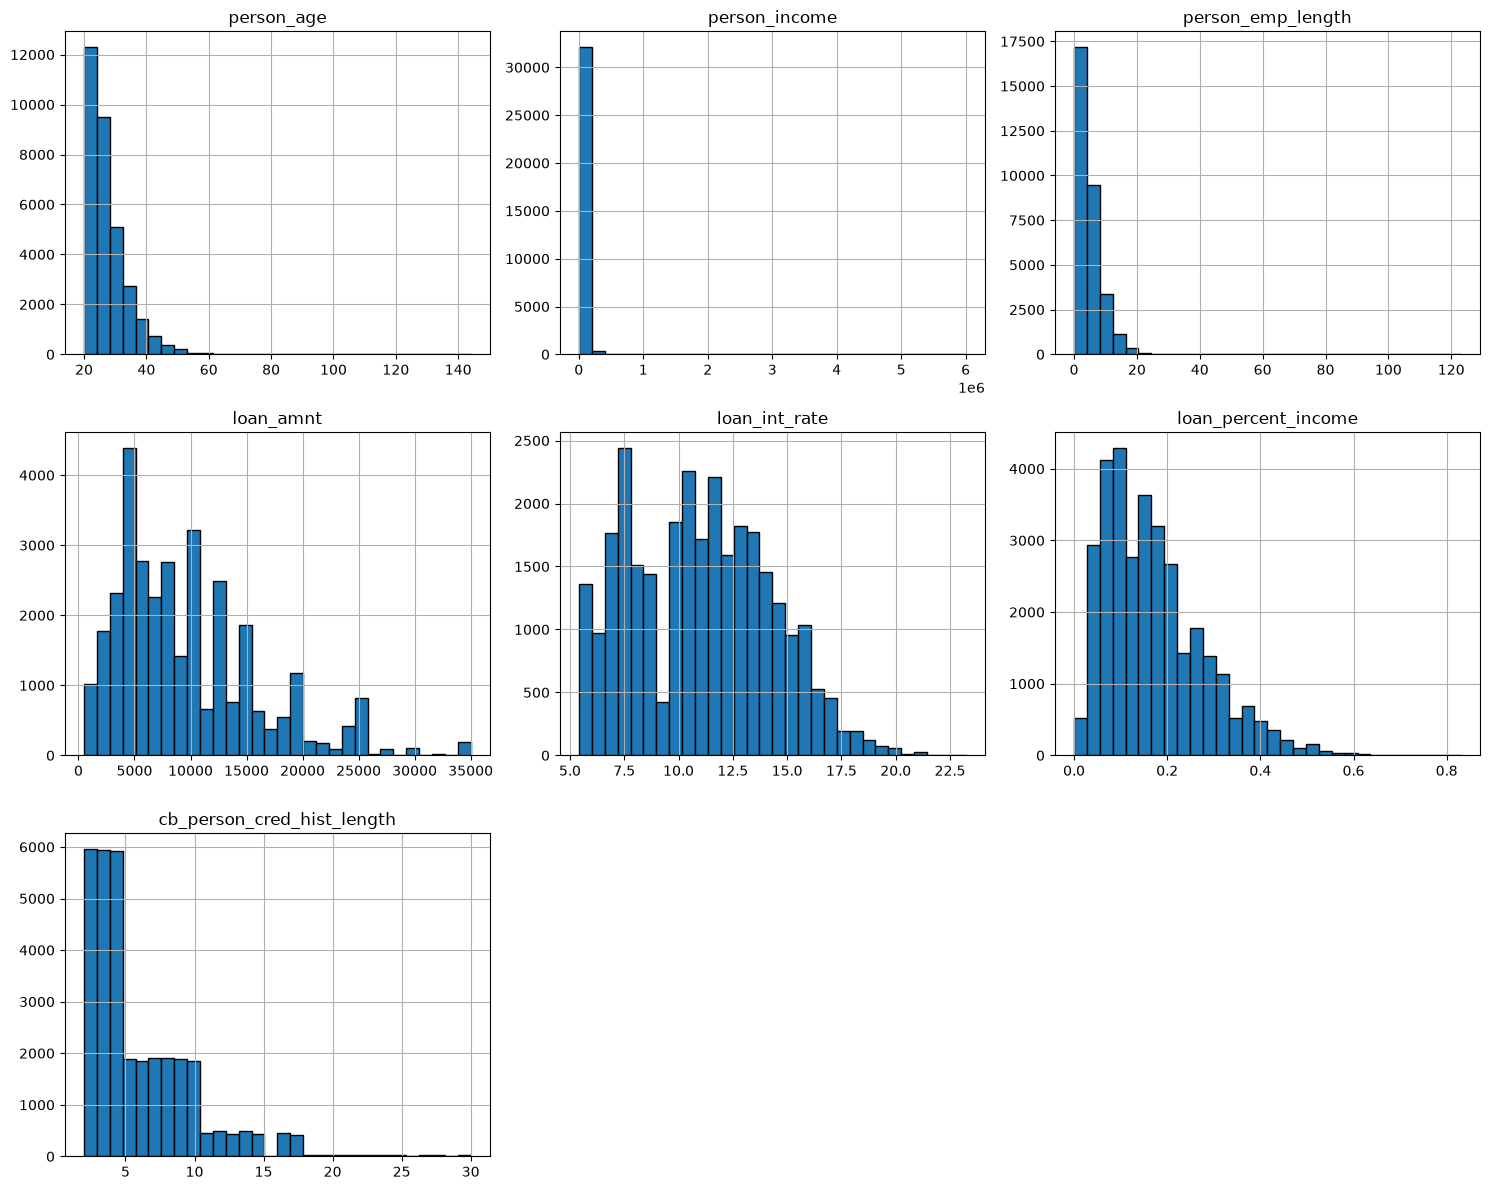

In [4]:
numerical_columns = [
    'person_age',
    'person_income',
    'person_emp_length',
    'loan_amnt',
    'loan_int_rate',
    'loan_percent_income',
    'cb_person_cred_hist_length'
]

df[numerical_columns].hist(
    figsize=(15, 12),
    bins=30,
    edgecolor='black'
)

plt.tight_layout()
save_eda_figure("Figure_1_Numerical_Distributions")
plt.show()

Figure saved: D:\AI-Engineering\Loan_Default_Research\results\figures\Notebook_01_EDA\Figure_2_Numerical_Boxplots.png


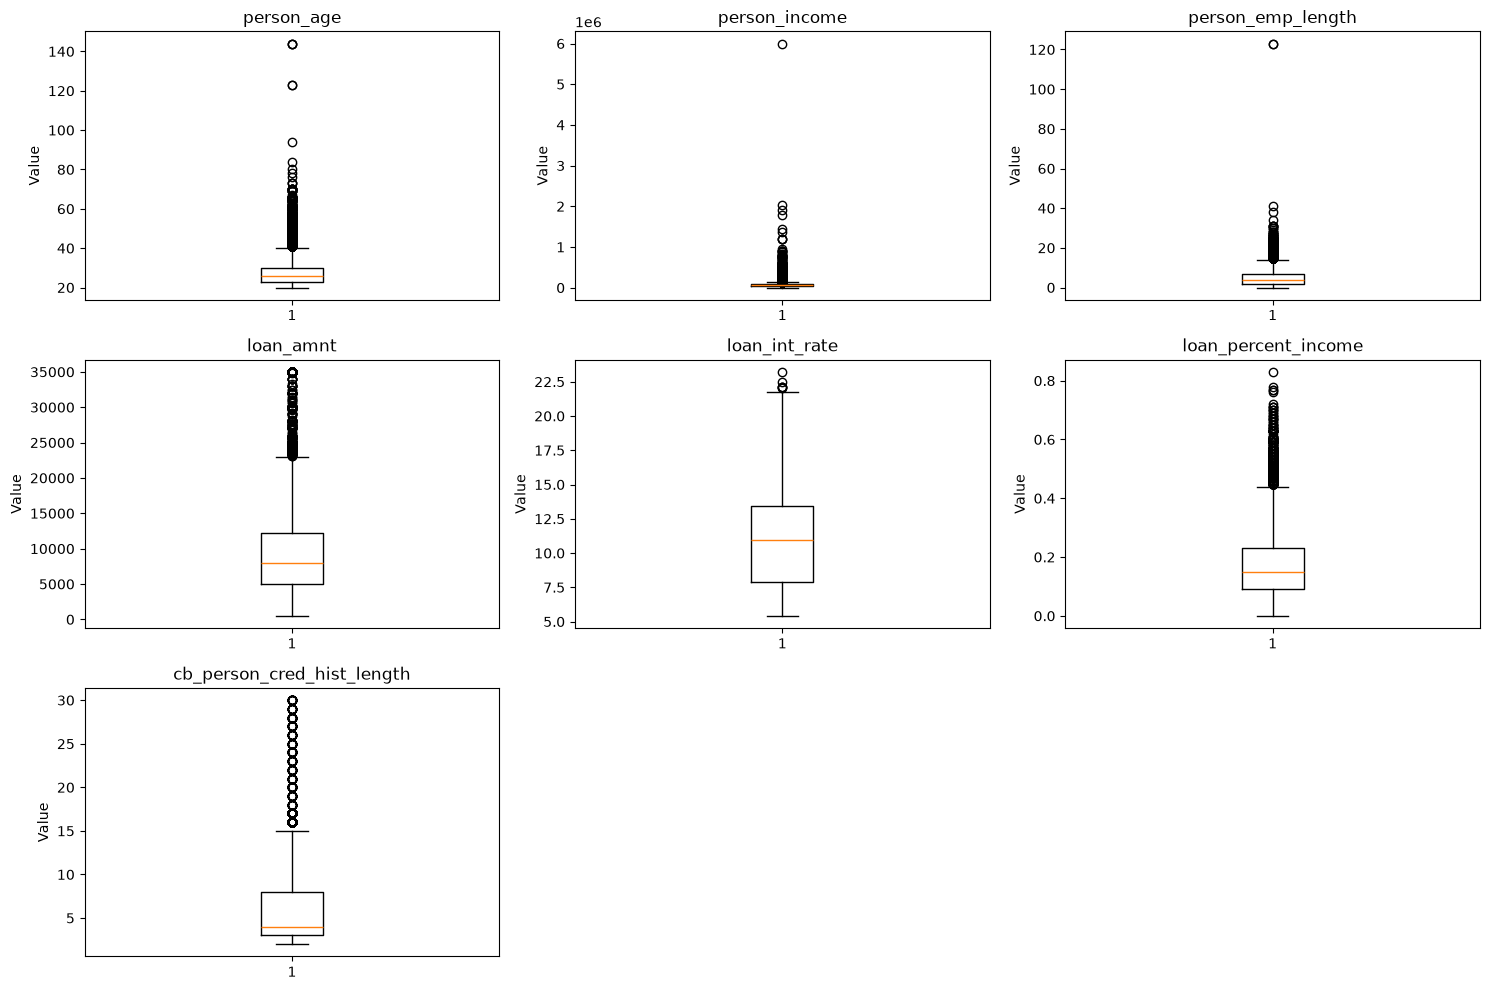

In [5]:
plt.figure(figsize=(15, 10))

for i, column in enumerate(numerical_columns, 1):
    plt.subplot(3, 3, i)

    plt.boxplot(df[column].dropna())
    plt.title(column)
    plt.ylabel('Value')

plt.tight_layout()
save_eda_figure("Figure_2_Numerical_Boxplots")
plt.show()

In [6]:
outlier_results = []

for column in numerical_columns:

    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = df[
        (df[column] < lower_bound) |
        (df[column] > upper_bound)
    ]

    outlier_results.append({
        'Column': column,
        'Lower Bound': lower_bound,
        'Upper Bound': upper_bound,
        'Outlier Count': len(outliers),
        'Outlier Percentage': (
    len(outliers) / df[column].notna().sum()
) * 100
    })

outlier_df = pd.DataFrame(outlier_results)

display(outlier_df.round(2))

,Column,Lower Bound,Upper Bound,Outlier Count,Outlier Percentage
0,person_age,12.50,40.50,1494,4.59
1,person_income,-22550.00,140250.00,1484,4.55
2,person_emp_length,-5.50,14.50,853,2.69
3,loan_amnt,-5800.00,23000.00,1689,5.18
4,loan_int_rate,-0.46,21.83,6,0.02
5,loan_percent_income,-0.12,0.44,651,2.00
6,cb_person_cred_hist_length,-4.50,15.50,1142,3.51


In [7]:
# Calculate skewness of numerical columns

skewness = df[numerical_columns].skew()

skewness_summary = pd.DataFrame({
    'Skewness': skewness,
    'Distribution': skewness.apply(
        lambda x: 'Approximately symmetric' if -0.5 <= x <= 0.5
        else 'Moderately skewed' if -1 <= x <= 1
        else 'Highly skewed'
    )
})

display(skewness_summary.sort_values(
    by='Skewness',
    ascending=False
))

,Skewness,Distribution
person_income,32.865349,Highly skewed
person_emp_length,2.614455,Highly skewed
person_age,2.581393,Highly skewed
cb_person_cred_hist_length,1.661790,Highly skewed
loan_amnt,1.192477,Highly skewed
loan_percent_income,1.064669,Highly skewed
loan_int_rate,0.208550,Approximately symmetric


In [8]:
# Employment length should not exceed the person's age

suspicious_employment = df[
    df['person_emp_length'] > df['person_age']
]

print("Records where employment length exceeds age:",
      len(suspicious_employment))

display(suspicious_employment.head(15))


# Inspect unusually high ages
print("Records with age above 100:")
display(df[df['person_age'] > 100])


# Inspect unusually long credit histories
print("Records where credit history exceeds age:")
display(df[
    df['cb_person_cred_hist_length'] > df['person_age']
])

Records where employment length exceeds age: 2


,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length
0,22,59000,RENT,123.0,PERSONAL,D,35000,16.02,1,0.59,Y,3
210,21,192000,MORTGAGE,123.0,VENTURE,A,20000,6.54,0,0.10,N,4


Records with age above 100:


,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length
81,144,250000,RENT,4.0,VENTURE,C,4800,13.57,0,0.02,N,3
183,144,200000,MORTGAGE,4.0,EDUCATION,B,6000,11.86,0,0.03,N,2
575,123,80004,RENT,2.0,EDUCATION,B,20400,10.25,0,0.25,N,3
747,123,78000,RENT,7.0,VENTURE,B,20000,NaN,0,0.26,N,4
32297,144,6000000,MORTGAGE,12.0,PERSONAL,C,5000,12.73,0,0.00,N,25


Records where credit history exceeds age:


,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length


## 3. Data Quality Assessment and Cleaning

Potentially invalid observations are investigated before
cleaning. These include implausible applicant ages,
unusually long employment durations and employment
lengths exceeding applicant age.

Identified invalid values are converted to missing
values rather than deleting entire records. Exact
duplicate records are subsequently removed.

In [9]:
# Create a working copy
df_clean = df.copy()

# Inspect suspicious age values
print("Suspicious ages:")
display(
    df_clean[df_clean['person_age'] > 100]
    [['person_age', 'person_income',
      'person_emp_length', 'loan_status']]
)

# Inspect suspicious employment lengths
print("\nSuspicious employment lengths:")
display(
    df_clean[df_clean['person_emp_length'] > 50]
    [['person_age', 'person_emp_length', 'loan_status']]
)

# Inspect the highest income records
print("\nHighest income records:")
display(
    df_clean.nlargest(10, 'person_income')
    [['person_age', 'person_income',
      'loan_amnt', 'loan_percent_income', 'loan_status']]
)

Suspicious ages:


,person_age,person_income,person_emp_length,loan_status
81,144,250000,4.0,0
183,144,200000,4.0,0
575,123,80004,2.0,0
747,123,78000,7.0,0
32297,144,6000000,12.0,0



Suspicious employment lengths:


,person_age,person_emp_length,loan_status
0,22,123.0,1
210,21,123.0,0



Highest income records:


,person_age,person_income,loan_amnt,loan_percent_income,loan_status
32297,144,6000000,5000,0.00,0
30049,42,2039784,8450,0.00,0
32546,60,1900000,1500,0.00,0
32497,63,1782000,12025,0.01,0
31924,44,1440000,6400,0.00,0
31922,47,1362000,6600,0.00,0
17833,32,1200000,12000,0.01,0
29119,36,1200000,10000,0.01,0
29120,40,1200000,10000,0.01,0
17834,34,948000,2000,0.00,0


In [10]:
print("Ages above 100:",
      (df_clean['person_age'] > 100).sum())

print("Employment lengths above 50:",
      (df_clean['person_emp_length'] > 50).sum())

print("Missing values before correction:")
print(df_clean.isnull().sum())

Ages above 100: 5
Employment lengths above 50: 2
Missing values before correction:
person_age                       0
person_income                    0
person_home_ownership            0
person_emp_length              895
loan_intent                      0
loan_grade                       0
loan_amnt                        0
loan_int_rate                 3116
loan_status                      0
loan_percent_income              0
cb_person_default_on_file        0
cb_person_cred_hist_length       0
dtype: int64


In [11]:
# Correct impossible age values
df_clean.loc[
    df_clean['person_age'] > 100,
    'person_age'
] = np.nan

# Correct employment length greater than 50
df_clean.loc[
    df_clean['person_emp_length'] > 50,
    'person_emp_length'
] = np.nan

# Correct employment length greater than age
invalid_employment = (
    df_clean['person_age'].notna() &
    (
        df_clean['person_emp_length'] >
        df_clean['person_age']
    )
)

df_clean.loc[
    invalid_employment,
    'person_emp_length'
] = np.nan

print("Missing values after corrections:")
display(df_clean.isnull().sum())

print("\nDataset shape:", df_clean.shape)

Missing values after corrections:


person_age                       5
person_income                    0
person_home_ownership            0
person_emp_length              897
loan_intent                      0
loan_grade                       0
loan_amnt                        0
loan_int_rate                 3116
loan_status                      0
loan_percent_income              0
cb_person_default_on_file        0
cb_person_cred_hist_length       0
dtype: int64


Dataset shape: (32581, 12)


In [12]:
# Check dataset before removing duplicates
print("Before removing duplicates:")
print("Dataset shape:", df_clean.shape)
print("Duplicate rows:", df_clean.duplicated().sum())

print("\nTarget distribution before removal:")
display(df_clean['loan_status'].value_counts())

# Remove exact duplicate rows
df_clean = df_clean.drop_duplicates().copy()

# Check dataset after removing duplicates
print("\nAfter removing duplicates:")
print("Dataset shape:", df_clean.shape)
print("Duplicate rows:", df_clean.duplicated().sum())

print("\nTarget distribution after removal:")
display(df_clean['loan_status'].value_counts())

Before removing duplicates:
Dataset shape: (32581, 12)
Duplicate rows: 165

Target distribution before removal:


loan_status
0    25473
1     7108
Name: count, dtype: int64


After removing duplicates:
Dataset shape: (32416, 12)
Duplicate rows: 0

Target distribution after removal:


loan_status
0    25327
1     7089
Name: count, dtype: int64

## 4. Missing Value Analysis

Missing values are examined after data cleaning.
Their distribution is investigated across the target
classes to understand whether missingness is associated
with loan default status.

Missing values are retained for subsequent
imputation within the machine-learning pipelines
to avoid data leakage.

In [13]:
# Calculate missing values
missing_count = df_clean.isnull().sum()

# Calculate missing percentages
missing_percentage = (
    df_clean.isnull().sum() / len(df_clean)
) * 100

# Create a summary table
missing_summary = pd.DataFrame({
    'Missing Values': missing_count,
    'Missing Percentage (%)': missing_percentage
})

# Display columns containing missing values
missing_summary = missing_summary[
    missing_summary['Missing Values'] > 0
].sort_values(by='Missing Percentage (%)', ascending=False)

display(missing_summary)

,Missing Values,Missing Percentage (%)
loan_int_rate,3095,9.547754
person_emp_length,889,2.742473
person_age,5,0.015424


In [14]:
# Compare missing values with loan default status

for column in [
    'loan_int_rate',
    'person_emp_length',
    'person_age'
]:

    print(f"\nMissingness analysis for: {column}")

    # Create a temporary indicator
    missing_indicator = df_clean[column].isnull()

    # Calculate default rate for missing and non-missing groups
    analysis = df_clean.groupby(missing_indicator)['loan_status'].agg(
        ['count', 'mean']
    )

    analysis.index = ['Not Missing', 'Missing']

    analysis['Default Rate (%)'] = analysis['mean'] * 100

    display(analysis)


Missingness analysis for: loan_int_rate


,count,mean,Default Rate (%)
Not Missing,29321,0.219911,21.991064
Missing,3095,0.207108,20.710824



Missingness analysis for: person_emp_length


,count,mean,Default Rate (%)
Not Missing,31527,0.21591,21.591017
Missing,889,0.31721,31.721035



Missingness analysis for: person_age


,count,mean,Default Rate (%)
Not Missing,32411,0.218722,21.872204
Missing,5,0.000000,0.000000


In [15]:
from scipy.stats import chi2_contingency

columns_to_check = [
    'loan_int_rate',
    'person_emp_length'
]

for column in columns_to_check:

    print(f"\nMissingness test: {column}")

    missing_indicator = df_clean[column].isnull()

    contingency_table = pd.crosstab(
        missing_indicator,
        df_clean['loan_status']
    )

    display(contingency_table)

    chi2, p_value, dof, expected = chi2_contingency(
        contingency_table
    )
    
    print("Chi-square statistic:", round(chi2, 4))
    print("Degrees of freedom:", dof)
    print("P-value:", p_value)
    
    if (expected < 5).any():
        print("Warning: Some expected frequencies are below 5.")
    else:
        print("All expected frequencies are at least 5.")


Missingness test: loan_int_rate


loan_status,0,1
loan_int_rate,,
False,22873,6448
True,2454,641


Chi-square statistic: 2.611
Degrees of freedom: 1
P-value: 0.10612338220098938
All expected frequencies are at least 5.

Missingness test: person_emp_length


loan_status,0,1
person_emp_length,,
False,24720,6807
True,607,282


Chi-square statistic: 51.3361
Degrees of freedom: 1
P-value: 7.783141266222232e-13
All expected frequencies are at least 5.


In [16]:
# Check whether missing values occur together

missing_pattern = df_clean[
    ['loan_int_rate', 'person_emp_length', 'person_age']
].isnull()


print("\nNumber of records with missing values in each combination:")

missing_pattern_counts = (
    missing_pattern.value_counts()
    .reset_index(name='Count')
)

display(missing_pattern_counts)


Number of records with missing values in each combination:


,loan_int_rate,person_emp_length,person_age,Count
0,False,False,False,28495
1,True,False,False,3027
2,False,True,False,822
3,True,True,False,67
4,False,False,True,4
5,True,False,True,1


## 5. Post-Cleaning Validation

The cleaned dataset is checked again for invalid
values, negative financial amounts, inconsistent
employment durations and duplicate records.

Remaining IQR-based outliers are retained because
they may represent valid financial observations.

In [17]:
# Post-cleaning validation

print("1. Invalid ages (above 100):")
print((df_clean['person_age'] > 100).sum())

print("\n2. Employment lengths above 50:")
print((df_clean['person_emp_length'] > 50).sum())

print("\n3. Negative employment lengths:")
print((df_clean['person_emp_length'] < 0).sum())

print("\n4. Employment length greater than age:")
print(
    (
        df_clean['person_emp_length'] >
        df_clean['person_age']
    ).sum()
)

print("\n5. Negative income:")
print((df_clean['person_income'] < 0).sum())

print("\n6. Negative loan amounts:")
print((df_clean['loan_amnt'] < 0).sum())

print("\n7. Invalid loan percentages:")
print(
    (
        (df_clean['loan_percent_income'] < 0) |
        (df_clean['loan_percent_income'] > 1)
    ).sum()
)

print("\n8. Remaining duplicate rows:")
print(df_clean.duplicated().sum())

1. Invalid ages (above 100):
0

2. Employment lengths above 50:
0

3. Negative employment lengths:
0

4. Employment length greater than age:
0

5. Negative income:
0

6. Negative loan amounts:
0

7. Invalid loan percentages:
0

8. Remaining duplicate rows:
0


In [18]:
# Numerical features to investigate
numeric_features = [
    'person_age',
    'person_income',
    'person_emp_length',
    'loan_amnt',
    'loan_int_rate',
    'loan_percent_income',
    'cb_person_cred_hist_length'
]

outlier_results = []

for column in numeric_features:

    # Calculate Q1 and Q3
    Q1 = df_clean[column].quantile(0.25)
    Q3 = df_clean[column].quantile(0.75)

    # Calculate IQR
    IQR = Q3 - Q1

    # Calculate lower and upper bounds
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    # Identify outliers
    outliers = df_clean[
        (df_clean[column] < lower_bound) |
        (df_clean[column] > upper_bound)
    ]

    outlier_results.append({
        'Feature': column,
        'Lower Bound': lower_bound,
        'Upper Bound': upper_bound,
        'Outlier Count': len(outliers),
        'Outlier Percentage (%)': (
            len(outliers) / df_clean[column].notna().sum()
        ) * 100
    })

outlier_summary = pd.DataFrame(outlier_results)

display(outlier_summary.round(3))

,Feature,Lower Bound,Upper Bound,Outlier Count,Outlier Percentage (%)
0,person_age,12.500,40.500,1486,4.585
1,person_income,-22472.000,140232.000,1478,4.559
2,person_emp_length,-5.500,14.500,850,2.696
3,loan_amnt,-5875.000,23125.000,1679,5.180
4,loan_int_rate,-0.455,21.825,6,0.020
5,loan_percent_income,-0.120,0.440,650,2.005
6,cb_person_cred_hist_length,-4.500,15.500,1139,3.514


## 6. Loan-to-Income Ratio Consistency Analysis

The provided loan-to-income ratio is compared with
the independently calculated ratio obtained by
dividing loan amount by annual income.

Discrepancies are examined across default and
non-default groups to identify potential data-quality
issues. The original feature is retained because
its discrepancies require further investigation
rather than automatic replacement.

An absolute difference threshold of 0.005 is used as
an exploratory screening criterion to identify
potentially notable discrepancies. This threshold
is not treated as definitive proof of incorrect data.

In [19]:
# Calculate loan-to-income ratio independently

calculated_ratios = (
    df_clean['loan_amnt'] /
    df_clean['person_income'].replace(0, np.nan)
)

# Compare original and calculated ratios
ratio_comparison = pd.DataFrame({
    'Original_Ratio': df_clean['loan_percent_income'],
    'Calculated_Ratio': calculated_ratios
})

# Calculate absolute difference
ratio_comparison['Absolute_Difference'] = (
    ratio_comparison['Original_Ratio'] -
    ratio_comparison['Calculated_Ratio']
).abs()

# Summary statistics
print("Ratio comparison summary:")

display(
    ratio_comparison['Absolute_Difference']
    .describe()
    .to_frame()
)

# Count differences greater than 0.005
print(
    "\nRecords with absolute difference greater than 0.005:",
    (
        ratio_comparison['Absolute_Difference'] > 0.005
    ).sum()
)

# Count missing original ratios
print(
    "\nMissing original ratios:",
    ratio_comparison['Original_Ratio'].isna().sum()
)

# Count missing calculated ratios
print(
    "Missing calculated ratios:",
    ratio_comparison['Calculated_Ratio'].isna().sum()
)

Ratio comparison summary:


,Absolute_Difference
count,32416.000000
mean,0.002764
std,0.004101
min,0.000000
25%,0.001111
50%,0.002500
75%,0.003673
max,0.093382



Records with absolute difference greater than 0.005: 911

Missing original ratios: 0
Missing calculated ratios: 0


In [20]:
# Inspect records with the largest ratio differences

ratio_comparison['Absolute_Difference'] = (
    ratio_comparison['Original_Ratio'] -
    ratio_comparison['Calculated_Ratio']
).abs()

largest_ratio_differences = (
    ratio_comparison
    .nlargest(10, 'Absolute_Difference')
    .join(
        df_clean[
            [
                'person_age',
                'person_income',
                'loan_amnt',
                'loan_status'
            ]
        ]
    )
)

display(
    largest_ratio_differences[
        [
            'person_age',
            'person_income',
            'loan_amnt',
            'Original_Ratio',
            'Calculated_Ratio',
            'Absolute_Difference',
            'loan_status'
        ]
    ].round(5)
)

,person_age,person_income,loan_amnt,Original_Ratio,Calculated_Ratio,Absolute_Difference,loan_status
4,24.0,54400,35000,0.55,0.64338,0.09338,1
11873,22.0,60350,35000,0.49,0.57995,0.08995,1
11253,23.0,56403,30000,0.45,0.53189,0.08189,1
13005,24.0,63750,35000,0.47,0.54902,0.07902,1
24150,31.0,54400,27050,0.42,0.49724,0.07724,1
13856,23.0,72250,35000,0.41,0.48443,0.07443,1
40,26.0,62050,30000,0.41,0.48348,0.07348,1
48,22.0,66300,30000,0.38,0.45249,0.07249,1
13182,24.0,66300,30000,0.38,0.45249,0.07249,1
16670,24.0,66300,30000,0.38,0.45249,0.07249,1


In [21]:
# Compare ratio discrepancies between default and non-default groups

ratio_comparison['loan_status'] = df_clean['loan_status']

ratio_comparison['Large_Difference'] = (
    ratio_comparison['Absolute_Difference'] > 0.005
)

discrepancy_summary = (
    ratio_comparison
    .groupby('loan_status')
    .agg(
        Total_Records=('Absolute_Difference', 'count'),
        Mean_Difference=('Absolute_Difference', 'mean'),
        Median_Difference=('Absolute_Difference', 'median'),
        Large_Differences=('Large_Difference', 'sum')
    )
)

discrepancy_summary['Large_Difference_Percentage'] = (
    discrepancy_summary['Large_Differences'] /
    discrepancy_summary['Total_Records'] * 100
)

display(discrepancy_summary.round(4))

,Total_Records,Mean_Difference,Median_Difference,Large_Differences,Large_Difference_Percentage
loan_status,,,,,
0,25327,0.0024,0.0024,385,1.5201
1,7089,0.0042,0.0027,526,7.4199


In [22]:
# Create a contingency table
contingency_table = pd.crosstab(
    ratio_comparison['loan_status'],
    ratio_comparison['Large_Difference']
)

print("Contingency Table:")
display(contingency_table)

# Perform chi-square test
chi2, p_value, dof, expected = chi2_contingency(
    contingency_table
)

print("\nChi-square statistic:", chi2)
print("Degrees of freedom:", dof)
print("P-value:", p_value)

# Calculate Cramer's V effect size
n = contingency_table.to_numpy().sum()

cramers_v = np.sqrt(chi2 / n)

print("Cramer's V:", round(cramers_v, 4))

# Interpret the result
if p_value < 0.05:
    print("\nThere is a statistically significant association.")
else:
    print("\nNo statistically significant association was found.")

Contingency Table:


Large_Difference,False,True
loan_status,,
0,24942,385
1,6563,526



Chi-square statistic: 703.6864121813569
Degrees of freedom: 1
P-value: 4.721419458164031e-155
Cramer's V: 0.1473

There is a statistically significant association.


## 7. Correlation Analysis

Spearman correlation is used to examine relationships
between numerical variables and the loan default
target. A correlation heatmap is also generated to
visualize relationships among numerical predictors.

These correlations describe associations and do not
establish causal relationships.

In [23]:
# Calculate Spearman correlation between numerical features

correlation_matrix = df_clean.corr(
    method='spearman',
    numeric_only=True
)

# Display correlations with the target variable
target_correlations = (
    correlation_matrix['loan_status']
    .drop('loan_status')
    .sort_values(key=abs, ascending=False)
)

print("Spearman correlation with loan_status:")

display(
    target_correlations.to_frame(
        name='Spearman Correlation'
    ).round(4)
)

Spearman correlation with loan_status:


,Spearman Correlation
loan_int_rate,0.3209
loan_percent_income,0.3165
person_income,-0.2722
person_emp_length,-0.0980
loan_amnt,0.0845
person_age,-0.0346
cb_person_cred_hist_length,-0.0250


Figure saved: D:\AI-Engineering\Loan_Default_Research\results\figures\Notebook_01_EDA\Figure_3_Spearman_Correlation.png


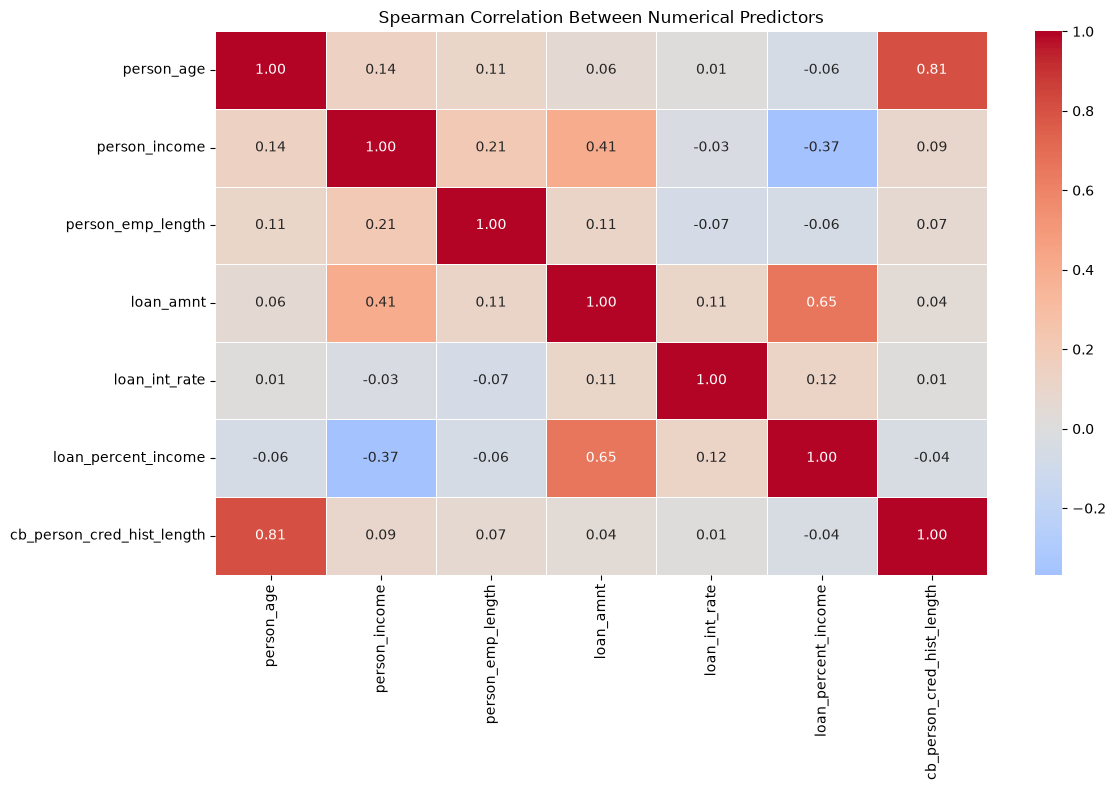

In [24]:
# Select numerical predictors (exclude target)
numeric_predictors = df_clean.select_dtypes(
    include='number'
).drop(columns=['loan_status'])

# Calculate Spearman correlation
predictor_corr = numeric_predictors.corr(
    method='spearman'
)

# Plot correlation heatmap
plt.figure(figsize=(12, 8))

sns.heatmap(
    predictor_corr,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    center=0,
    linewidths=0.5
)

plt.title('Spearman Correlation Between Numerical Predictors')
plt.tight_layout()
save_eda_figure("Figure_3_Spearman_Correlation")
plt.show()

Figure saved: D:\AI-Engineering\Loan_Default_Research\results\figures\Notebook_01_EDA\Figure_4_Loan_Status_Distribution.png


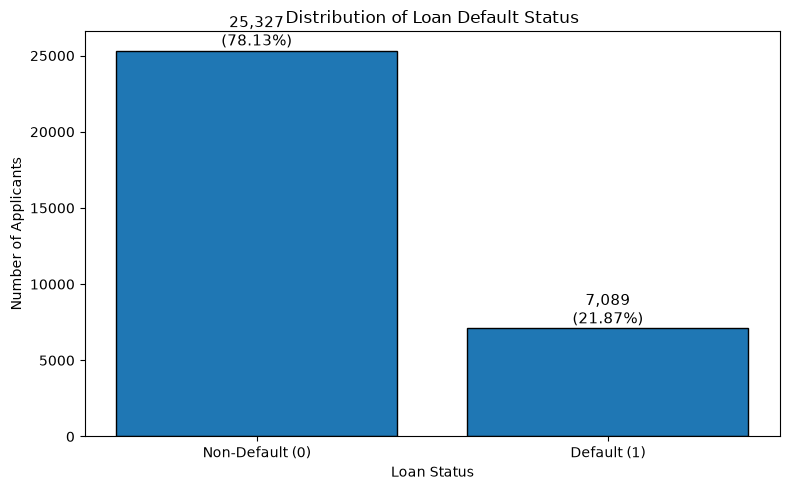

In [25]:
# FIGURE 4: LOAN STATUS DISTRIBUTION

# Calculate loan status counts
loan_status_counts = df_clean['loan_status'].value_counts().sort_index()

# Calculate percentages
loan_status_percentages = (
    df_clean['loan_status'].value_counts(normalize=True).sort_index() * 100
)

# Create bar chart
plt.figure(figsize=(8, 5))

bars = plt.bar(
    ['Non-Default (0)', 'Default (1)'],
    loan_status_counts.values,
    edgecolor='black'
)

# Add count and percentage labels
for bar, count, percentage in zip(
    bars,
    loan_status_counts.values,
    loan_status_percentages.values
):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f'{count:,}\n({percentage:.2f}%)',
        ha='center',
        va='bottom',
        fontsize=11
    )

plt.title('Distribution of Loan Default Status')
plt.xlabel('Loan Status')
plt.ylabel('Number of Applicants')
plt.tight_layout()

save_eda_figure("Figure_4_Loan_Status_Distribution")

plt.show()

In [26]:
# Create processed directory
processed_dir = project_dir / "datasets" / "processed"
processed_dir.mkdir(parents=True, exist_ok=True)

# Save cleaned dataset
credit_output_path = (
    processed_dir / "credit_risk_cleaned.csv"
)

df_clean.to_csv(credit_output_path, index=False)

print("Cleaned dataset saved successfully!")
print("Location:", credit_output_path)
print("Final shape:", df_clean.shape)
print("Remaining missing values:",
      df_clean.isnull().sum().sum())
print("Remaining duplicates:",
      df_clean.duplicated().sum())

print("\nFinal target distribution:")
display(df_clean['loan_status'].value_counts())

print("\nFinal target percentages:")
display(
    (df_clean['loan_status'].value_counts(normalize=True) * 100)
    .round(2)
)

Cleaned dataset saved successfully!
Location: D:\AI-Engineering\Loan_Default_Research\datasets\processed\credit_risk_cleaned.csv
Final shape: (32416, 12)
Remaining missing values: 3989
Remaining duplicates: 0

Final target distribution:


loan_status
0    25327
1     7089
Name: count, dtype: int64


Final target percentages:


loan_status
0    78.13
1    21.87
Name: proportion, dtype: float64

## 8. Summary of Data Inspection and Preprocessing

The original Credit Risk dataset contained 32,581
records and 12 features. During preprocessing, 165
duplicate records were removed, reducing the dataset
to 32,416 records.

Five implausible age values and employment-duration
inconsistencies were converted to missing values.
Missing values were retained for subsequent
imputation within the machine-learning pipelines.

The final dataset contains 32,416 records and 12
columns, with 3,989 missing values and no remaining
duplicate records. The target variable consists of
25,327 non-default cases (78.13%) and 7,089 default
cases (21.87%).

The processed dataset is saved for subsequent
statistical data fusion and machine-learning
experiments.